# Importance Measures for Series-Parallel Ensembles (Binary)

This notebook computes structural importance measures for SP ensembles
and validates whether they predict which base model is most worth optimizing.

In [1]:
import gc
import glob
import os
import random
import time
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
from scipy.stats import rankdata, spearmanr
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier

warnings.filterwarnings("ignore")

import sklearn, sys
print(f'scikit-learn: {sklearn.__version__}, numpy: {np.__version__}, Python: {sys.version.split()[0]}')

scikit-learn: 1.7.2, numpy: 2.0.0, Python: 3.12.4


In [2]:
from series_parallel import *
from series_parallel import SeriesParallelEnsemble, execute_binary
from series_parallel.importance import (
    birnbaum_importance,
    compute_all_importances,
    degradation_importance,
    flip_importance,
    oracle_importance,
    _system_reliability,
)
from series_parallel.scoring import _build_truth_tables, _predictions_to_pattern_indices

In [3]:
FOLDER_DATASETS = "datasets_binary/"

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

def create_and_train_models(train_X, train_Y, random_state=123):
    """Create 8 diverse base models and train them with default hyperparameters."""
    seed_everything(random_state)
    models = [
        ("KNN",    KNeighborsClassifier(n_neighbors=5)),
        ("SVC",    SVC(kernel="rbf", random_state=random_state)),
        ("Ridge",  RidgeClassifier(random_state=random_state)),
        ("DT",     DecisionTreeClassifier(random_state=random_state)),
        ("MLP",    MLPClassifier(random_state=random_state, max_iter=1000, solver="lbfgs")),
        ("LogReg", LogisticRegression(random_state=random_state, max_iter=1000)),
        ("LDA",    LinearDiscriminantAnalysis()),
        ("ETC",    ExtraTreeClassifier(random_state=random_state)),
    ]
    for name, model in models:
        model.fit(train_X, train_Y)
    return models

def load_and_split(dataset_path, random_state=123):
    """Load CSV dataset and split 60/20/20 stratified."""
    df = pd.read_csv(dataset_path)
    y = df["target_end"].values
    X = df.drop(columns="target_end").values
    train_X, test_X, train_Y, test_Y = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=random_state)
    train_X, val_X, train_Y, val_Y = train_test_split(
        train_X, train_Y, test_size=0.25, stratify=train_Y, random_state=random_state)
    return train_X, train_Y, val_X, val_Y, test_X, test_Y

def sort_models_by_val(models, val_X, val_Y, metric):
    """Sort models by descending validation score."""
    scored = [(name, model, metric(val_Y, model.predict(val_X))) for name, model in models]
    scored.sort(key=lambda x: x[2], reverse=True)
    return [(name, model) for name, model, _ in scored]

## Experimental design

## Part 1: Single-dataset example

In [4]:
list_datasets = sorted(glob.glob("datasets_binary/*.csv"))
DEMO_DATASET = list_datasets[0]
METRIC = f1_score
RS = 123
N_DEMO = 5

print(f"Dataset: {os.path.basename(DEMO_DATASET)}")

train_X, train_Y, val_X, val_Y, test_X, test_Y = load_and_split(DEMO_DATASET, RS)
models = create_and_train_models(train_X, train_Y, RS)
models_sorted = sort_models_by_val(models, val_X, val_Y, METRIC)

print("\nBase model F1 on VAL:")
for name, model in models_sorted:
    print(f"  {name}: {METRIC(val_Y, model.predict(val_X)):.4f}")

# Take top-N models and fit SP ensemble (exhaustive)
estimators_sub = models_sorted[:N_DEMO]
sp = SeriesParallelEnsemble(estimators_sub, strategy="exhaustive")
sp.fit(val_X, val_Y, metric=METRIC, n_jobs=64)

print(f"\nBest SP tree: {sp.best_tree_as_string()}")
print(f"SP F1 on VAL:  {METRIC(val_Y, sp.predict(val_X)):.4f}")
print(f"SP F1 on TEST: {METRIC(test_Y, sp.predict(test_X)):.4f}")

Dataset: Bioresponse.csv

Base model F1 on VAL:
  SVC: 0.7786
  MLP: 0.7713
  KNN: 0.7554
  LogReg: 0.7295
  Ridge: 0.7123
  DT: 0.7062
  ETC: 0.7032
  LDA: 0.6857
  Loaded N=2: 2 trees
  Loaded N=3: 8 trees
  Loaded N=4: 52 trees
  Loaded N=5: 472 trees
  Loaded N=6: 5504 trees
  Loaded N=7: 78416 trees
  Loaded N=8: 1320064 trees

Best SP tree: [Paralelo, [Serie, [Paralelo, [Paralelo, SVC, Ridge], LogReg], KNN], MLP]
SP F1 on VAL:  0.7996
SP F1 on TEST: 0.8225


In [5]:
# Compute importance on VAL
model_names = [n for n, _ in estimators_sub]
val_preds = [m.predict(val_X) for _, m in estimators_sub]

# Reliabilities for Birnbaum = accuracy of each model on VAL
reliabilities = [accuracy_score(val_Y, p) for p in val_preds]

imp = compute_all_importances(
    val_preds, val_Y, sp._compiled_best, METRIC, model_names,
    tree_tuple=sp._best_tree_tuple, reliabilities=reliabilities)

# Also compute system reliability
sys_rel = _system_reliability(sp._best_tree_tuple, reliabilities)

# Compute actual oracle gains on TEST
test_preds = [m.predict(test_X) for _, m in estimators_sub]
test_preds_bool = [np.asarray(p, dtype=np.bool_) for p in test_preds]
Y_test_bool = np.asarray(test_Y, dtype=np.bool_)
baseline_test = METRIC(test_Y, execute_binary(sp._compiled_best, test_preds_bool))

actual_gains = np.empty(N_DEMO)
for i in range(N_DEMO):
    oracle_p = list(test_preds_bool)
    oracle_p[i] = Y_test_bool
    actual_gains[i] = METRIC(test_Y, execute_binary(sp._compiled_best, oracle_p)) - baseline_test

# Display results
print(f"Baseline ensemble F1 — VAL: {imp['baseline_score']:.4f}, TEST: {baseline_test:.4f}")
print(f"System reliability h(p) = {sys_rel:.4f}  (under independence assumption)\n")

imp_df = pd.DataFrame({
    "Model": model_names,
    "Val Accuracy": reliabilities,
    "Birnbaum": imp["birnbaum"],
    "B-Success": imp["birnbaum_success"],
    "B-Failure": imp["birnbaum_failure"],
    "Flip (VAL)": imp["flip"],
    "Oracle (VAL)": imp["oracle"],
    "Degrad (VAL)": imp["degradation"],
    "Actual Gain (TEST)": actual_gains,
})
print(imp_df.to_string(index=False))

# Sanity check: I_Bs + I_Bf == I_B
assert np.allclose(imp["birnbaum_success"] + imp["birnbaum_failure"], imp["birnbaum"]), \
    "Decomposition check failed: I_Bs + I_Bf != I_B"
print("\n✓ Decomposition check passed: I_Bs + I_Bf == I_B")

print()
for measure, vals in [("birnbaum", imp["birnbaum"]),
                       ("birn_success", imp["birnbaum_success"]),
                       ("birn_failure", imp["birnbaum_failure"]),
                       ("flip", imp["flip"]),
                       ("oracle", imp["oracle"]),
                       ("degradation", imp["degradation"])]:
    if np.std(vals) > 1e-12 and np.std(actual_gains) > 1e-12:
        rho, p = spearmanr(vals, actual_gains)
        print(f"  Spearman {measure:14s} vs actual TEST gains: rho={rho:+.4f}  (p={p:.4f})")


Baseline ensemble F1 — VAL: 0.7996, TEST: 0.8225
System reliability h(p) = 0.9274  (under independence assumption)

 Model  Val Accuracy  Birnbaum  B-Success  B-Failure  Flip (VAL)  Oracle (VAL)  Degrad (VAL)  Actual Gain (TEST)
   SVC      0.762667  0.016888   0.004008   0.012880    0.072000      0.025029      0.004592            0.015213
   MLP      0.745333  0.285072   0.072598   0.212473    0.496000      0.108930      0.045412            0.083987
   KNN      0.730667  0.249181   0.067113   0.182068    0.156000      0.041126      0.028295            0.047093
LogReg      0.705333  0.013602   0.004008   0.009594    0.049333      0.017724     -0.000448            0.005811
 Ridge      0.692000  0.013013   0.004008   0.009005    0.054667      0.019538      0.000455            0.008609

✓ Decomposition check passed: I_Bs + I_Bf == I_B

  Spearman birnbaum       vs actual TEST gains: rho=+0.9000  (p=0.0374)
  Spearman birn_success   vs actual TEST gains: rho=+0.8944  (p=0.0405)
  Spearman 

## Part 2 — Level 1: Best-tree validation across all datasets

In [7]:
def level1_experiment(dataset_path, metric, random_state, trees_dict, n_range=range(3, 9)):
    """Level 1: for each N, find best tree on VAL, compute importance vs oracle gains on TEST."""
    train_X, train_Y, val_X, val_Y, test_X, test_Y = load_and_split(dataset_path, random_state)
    models = create_and_train_models(train_X, train_Y, random_state)
    models_sorted = sort_models_by_val(models, val_X, val_Y, metric)

    results = []
    for N in n_range:
        if N not in trees_dict:
            continue
        estimators_sub = models_sorted[:N]
        model_names = [n for n, _ in estimators_sub]

        # Fit exhaustive SP ensemble
        sp = SeriesParallelEnsemble(estimators_sub, strategy="exhaustive", trees=trees_dict)
        sp.fit(val_X, val_Y, metric=metric, n_jobs=64)
        compiled = sp._compiled_best

        # Predictions
        val_preds = [m.predict(val_X) for _, m in estimators_sub]
        test_preds = [m.predict(test_X) for _, m in estimators_sub]
        test_preds_bool = [np.asarray(p, dtype=np.bool_) for p in test_preds]
        Y_test_bool = np.asarray(test_Y, dtype=np.bool_)

        # Reliabilities for Birnbaum (accuracy on VAL)
        reliabilities = [accuracy_score(val_Y, p) for p in val_preds]

        # Importance on VAL
        imp_flip = flip_importance(val_preds, compiled)
        imp_oracle = oracle_importance(val_preds, val_Y, compiled, metric)
        imp_degrad = degradation_importance(val_preds, val_Y, compiled, metric)
        imp_birn_decomp = birnbaum_importance(sp._best_tree_tuple, reliabilities, decompose=True)
        imp_birn = imp_birn_decomp["total"]
        imp_birn_s = imp_birn_decomp["success"]
        imp_birn_f = imp_birn_decomp["failure"]

        # Actual oracle gains on TEST
        baseline_test = metric(test_Y, execute_binary(compiled, test_preds_bool))
        actual_gains = np.empty(N)
        for i in range(N):
            op = list(test_preds_bool)
            op[i] = Y_test_bool
            actual_gains[i] = metric(test_Y, execute_binary(compiled, op)) - baseline_test

        row = {
            "dataset": os.path.basename(dataset_path),
            "random_state": random_state,
            "N": N,
            "baseline_val": metric(val_Y, execute_binary(compiled,
                [np.asarray(p, dtype=np.bool_) for p in val_preds])),
            "baseline_test": baseline_test,
            "tree": sp.best_tree_as_string(),
        }

        for name, imp_vals in [("birnbaum", imp_birn),
                                ("birn_success", imp_birn_s),
                                ("birn_failure", imp_birn_f),
                                ("flip", imp_flip),
                                ("oracle", imp_oracle),
                                ("degrad", imp_degrad)]:
            if np.std(imp_vals) > 1e-12 and np.std(actual_gains) > 1e-12:
                rho, pval = spearmanr(imp_vals, actual_gains)
            else:
                rho, pval = np.nan, np.nan
            row[f"spearman_{name}"] = rho
            row[f"pval_{name}"] = pval

        for i, mname in enumerate(model_names):
            row[f"birn_{mname}"] = imp_birn[i]
            row[f"birn_s_{mname}"] = imp_birn_s[i]
            row[f"birn_f_{mname}"] = imp_birn_f[i]
            row[f"flip_{mname}"] = imp_flip[i]
            row[f"oracle_val_{mname}"] = imp_oracle[i]
            row[f"degrad_{mname}"] = imp_degrad[i]
            row[f"gain_test_{mname}"] = actual_gains[i]

        results.append(row)
    return results


In [8]:
# Load trees once
trees_dict = load_trees('possible_trees_compact.gz')
print("Trees loaded:", {n: len(t) for n, t in sorted(trees_dict.items())})

list_datasets = sorted(glob.glob("datasets_binary/*.csv"))
NRUNS = 10        # Increase for final experiments (paper uses 10)
METRIC = f1_score
N_RANGE = range(3, 9)

all_level1 = []
for run in range(NRUNS):
    rs = 123 * (run + 1)
    for ds_path in list_datasets:
        try:
            rows = level1_experiment(ds_path, METRIC, rs, trees_dict, N_RANGE)
            for r in rows:
                r["run"] = run
            all_level1.extend(rows)
            print(f"[run={run}] {os.path.basename(ds_path)} OK")
        except Exception as e:
            print(f"FAILED: {os.path.basename(ds_path)} run={run}: {e}")

df1 = pd.DataFrame(all_level1)
df1.to_csv("importance_results_level1.csv", index=False)
print(f"\nLevel 1 done: {len(df1)} experiments")

  Loaded N=2: 2 trees
  Loaded N=3: 8 trees
  Loaded N=4: 52 trees
  Loaded N=5: 472 trees
  Loaded N=6: 5504 trees
  Loaded N=7: 78416 trees
  Loaded N=8: 1320064 trees
Trees loaded: {2: 2, 3: 8, 4: 52, 5: 472, 6: 5504, 7: 78416, 8: 1320064}
[run=0] Bioresponse.csv OK
[run=0] Contaminant.csv OK
[run=0] ECG5000.csv OK
[run=0] FICO.csv OK
[run=0] Insurance.csv OK
[run=0] Intersectional.csv OK
[run=0] Long.csv OK
[run=0] MagicTelescope.csv OK
[run=0] PhishingWebsites.csv OK
[run=0] Satellite.csv OK
[run=0] SpeedDating.csv OK
[run=0] Titanic.csv OK
[run=0] UCI.csv OK
[run=0] ada.csv OK
[run=0] churn.csv OK
[run=0] clean2.csv OK
[run=0] coil2000.csv OK
[run=0] compas.csv OK
[run=0] credit.csv OK
[run=0] default.csv OK
[run=0] dis.csv OK
[run=0] eeg.csv OK
[run=0] heloc.csv OK
[run=0] jasmine.csv OK
[run=0] jm1.csv OK
[run=0] kc1.csv OK
[run=0] kdd.csv OK
[run=0] kr.csv OK
[run=0] law.csv OK
[run=0] madeline.csv OK
[run=0] mc1.csv OK
[run=0] mushroom.csv OK
[run=0] national.csv OK
[run=0] p

In [9]:
print("=" * 70)
print("LEVEL 1: Spearman correlation — importance (VAL) vs oracle gains (TEST)")
print("=" * 70)

for measure in ["birnbaum", "birn_success", "birn_failure", "flip", "oracle", "degrad"]:
    col = f"spearman_{measure}"
    valid = df1[col].dropna()
    print(f"\n{measure.upper()} importance ({len(valid)} valid experiments):")
    print(f"  Mean Spearman:   {valid.mean():.4f}")
    print(f"  Median Spearman: {valid.median():.4f}")
    print(f"  Std:             {valid.std():.4f}")
    print(f"  Fraction > 0:    {(valid > 0).mean():.1%}")
    print(f"  Fraction > 0.5:  {(valid > 0.5).mean():.1%}")

print("\n" + "=" * 70)
print("Breakdown by N (ensemble size)")
print("=" * 70)
for N in sorted(df1["N"].unique()):
    sub = df1[df1["N"] == N]
    print(f"\n  N = {N}  ({len(sub)} experiments)")
    for measure in ["birnbaum", "birn_success", "birn_failure", "flip", "oracle", "degrad"]:
        col = f"spearman_{measure}"
        v = sub[col].dropna()
        if len(v) > 0:
            print(f"    {measure:14s}: mean={v.mean():+.4f}  median={v.median():+.4f}  >0: {(v>0).mean():.0%}")


LEVEL 1: Spearman correlation — importance (VAL) vs oracle gains (TEST)

BIRNBAUM importance (2317 valid experiments):
  Mean Spearman:   0.5008
  Median Spearman: 0.7000
  Std:             0.5544
  Fraction > 0:    84.5%
  Fraction > 0.5:  67.0%

BIRN_SUCCESS importance (2066 valid experiments):
  Mean Spearman:   0.6693
  Median Spearman: 0.8018
  Std:             0.4063
  Fraction > 0:    93.0%
  Fraction > 0.5:  77.4%

BIRN_FAILURE importance (2288 valid experiments):
  Mean Spearman:   0.5615
  Median Spearman: 0.7778
  Std:             0.5485
  Fraction > 0:    85.7%
  Fraction > 0.5:  74.0%

FLIP importance (2319 valid experiments):
  Mean Spearman:   0.8222
  Median Spearman: 0.9550
  Std:             0.3438
  Fraction > 0:    96.2%
  Fraction > 0.5:  87.9%

ORACLE importance (2263 valid experiments):
  Mean Spearman:   0.8514
  Median Spearman: 0.9701
  Std:             0.2956
  Fraction > 0:    97.2%
  Fraction > 0.5:  90.6%

DEGRAD importance (2290 valid experiments):
  Mean

## Part 3 — Level 2: Robustness across all SP trees

In [10]:
# =====================================================================
# Vectorized F1 from truth tables + pattern histogram
# =====================================================================
 
def _f1_all_trees(truth_tables_f64, pattern_indices, Y_bool):
    """F1 for all trees at once via histogram trick.  O(n_trees × 2^N)."""
    n_patterns = truth_tables_f64.shape[1]
    pos_hist = np.bincount(pattern_indices[Y_bool],
                           minlength=n_patterns).astype(np.float64)
    neg_hist = np.bincount(pattern_indices[~Y_bool],
                           minlength=n_patterns).astype(np.float64)
 
    TP = truth_tables_f64 @ pos_hist
    FP = truth_tables_f64 @ neg_hist
    FN = pos_hist.sum() - TP
    denom = 2.0 * TP + FP + FN
    return np.where(denom > 0, 2.0 * TP / denom, 0.0)


# =====================================================================
# Vectorized flip importance
# =====================================================================
 
def _flip_all_trees(truth_tables, pat_val, N, M_val, chunk=2000):
    """Flip importance for all trees × all models.  O(N × n_trees × 2^N)."""
    n_trees = truth_tables.shape[0]
    n_patterns = truth_tables.shape[1]
    sample_hist = np.bincount(pat_val, minlength=n_patterns).astype(np.float64)
 
    flip_imp = np.empty((n_trees, N), dtype=np.float64)
    for i in range(N):
        flipped_idx = np.arange(n_patterns) ^ (1 << i)
        for start in range(0, n_trees, chunk):
            end = min(start + chunk, n_trees)
            sl = truth_tables[start:end]
            xor = sl != sl[:, flipped_idx]
            flip_imp[start:end, i] = xor @ sample_hist / M_val
 
    return flip_imp
 

# =====================================================================
# Vectorized Birnbaum from truth tables
# =====================================================================
 
def _birnbaum_all_trees(truth_tables_f64, reliabilities, N):
    """Birnbaum importance for all trees at once using truth tables."""
    n_patterns = 1 << N
    p = np.asarray(reliabilities, dtype=np.float64)
 
    log_p = np.log(np.clip(p, 1e-15, 1.0))
    log_1mp = np.log(np.clip(1.0 - p, 1e-15, 1.0))
 
    patterns = np.arange(n_patterns, dtype=np.intp)
    bits = np.array([(patterns >> j) & 1 for j in range(N)], dtype=np.float64)
 
    log_w = bits.T @ log_p + (1.0 - bits.T) @ log_1mp
    w = np.exp(log_w)
 
    h_p = truth_tables_f64 @ w
 
    birn_total = np.empty((truth_tables_f64.shape[0], N), dtype=np.float64)
    birn_success = np.empty_like(birn_total)
    birn_failure = np.empty_like(birn_total)
 
    for i in range(N):
        mask_i = 1 << i
        has_bit_i = (patterns & mask_i).astype(bool)
        w_1i = np.where(has_bit_i, w / np.clip(p[i], 1e-15, 1.0), 0.0)
        w_0i = np.where(~has_bit_i, w / np.clip(1.0 - p[i], 1e-15, 1.0), 0.0)
 
        h_1i = truth_tables_f64 @ w_1i
        h_0i = truth_tables_f64 @ w_0i
 
        birn_total[:, i] = h_1i - h_0i
        birn_success[:, i] = h_1i - h_p
        birn_failure[:, i] = h_p - h_0i
 
    return birn_total, birn_success, birn_failure
 
    
# =====================================================================
# Vectorized Spearman correlation
# =====================================================================
 
def _rank_rows_fast(X):
    """Fully vectorized row-wise ranking (no Python loop over rows)."""
    order = np.argsort(X, axis=1, kind='quicksort')
    ranks = np.empty_like(X, dtype=np.float64)
    np.put_along_axis(ranks, order,
                      np.broadcast_to(np.arange(X.shape[1], dtype=np.float64),
                                      X.shape),
                      axis=1)
    return ranks
 
    
def _spearman_rowwise(A, B):
    """Spearman rho between each row of A and corresponding row of B."""
    n, k = A.shape
    if k < 2:
        return np.full(n, np.nan)
 
    rA = _rank_rows_fast(A)
    rB = _rank_rows_fast(B)
 
    rA_mean = rA.mean(axis=1, keepdims=True)
    rB_mean = rB.mean(axis=1, keepdims=True)
    dA = rA - rA_mean
    dB = rB - rB_mean
 
    num = (dA * dB).sum(axis=1)
    den = np.sqrt((dA**2).sum(axis=1) * (dB**2).sum(axis=1))
 
    return np.where(den > 1e-15, num / den, np.nan)


def _summarize_spearman(rho):
    """Compute summary statistics for a vector of Spearman correlations."""
    valid = rho[~np.isnan(rho)]
    if len(valid) == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan, 0
    return (np.mean(valid), np.median(valid), np.std(valid),
            np.mean(valid > 0), np.mean(valid > 0.5), len(valid))

    
# =====================================================================
# Main vectorized Level 2 experiment — returns AGGREGATED rows
# =====================================================================
 
def level2_experiment_vectorized(dataset_path, metric, random_state,
                                  trees_dict, N_values=[3, 4, 5, 6, 7, 8],
                                  load_and_split_fn=None,
                                  create_and_train_fn=None,
                                  sort_models_fn=None):
    """Level 2 fully vectorized: no per-tree Python loop.
    
    Returns one row per N with aggregated Spearman statistics,
    instead of one row per tree.
    """
    train_X, train_Y, val_X, val_Y, test_X, test_Y = load_and_split_fn(
        dataset_path, random_state)
    models = create_and_train_fn(train_X, train_Y, random_state)
    models_sorted = sort_models_fn(models, val_X, val_Y, metric)
 
    results = []
    t0 = time.time()
 
    for N in N_values:
        if N not in trees_dict:
            continue
 
        trees = trees_dict[N]
        n_trees = len(trees)
        estimators_sub = models_sorted[:N]
        M_val = len(val_Y)
        M_test = len(test_Y)
 
        # Cache predictions
        val_preds = [m.predict(val_X) for _, m in estimators_sub]
        test_preds = [m.predict(test_X) for _, m in estimators_sub]
        Y_val_bool = np.asarray(val_Y, dtype=np.bool_)
        Y_test_bool = np.asarray(test_Y, dtype=np.bool_)
        reliabilities = [accuracy_score(val_Y, p) for p in val_preds]
 
        # Build truth tables once: (n_trees, 2^N) bool
        truth_tables = _build_truth_tables(trees, N)
        tt_f64 = truth_tables.astype(np.float64)
 
        # Pattern indices
        pat_val = _predictions_to_pattern_indices(val_preds, N)
        pat_test = _predictions_to_pattern_indices(test_preds, N)
 
        # ---- 1. Baseline F1 for all trees ----
        baseline_val = _f1_all_trees(tt_f64, pat_val, Y_val_bool)
        baseline_test = _f1_all_trees(tt_f64, pat_test, Y_test_bool)
 
        # ---- 2. Oracle F1 for each model i ----
        oracle_val_scores = np.empty((n_trees, N), dtype=np.float64)
        oracle_test_scores = np.empty((n_trees, N), dtype=np.float64)
 
        for i in range(N):
            mask = 1 << i
            oracle_pv = (pat_val & ~mask) | (Y_val_bool.astype(np.intp) << i)
            oracle_pt = (pat_test & ~mask) | (Y_test_bool.astype(np.intp) << i)
            oracle_val_scores[:, i] = _f1_all_trees(tt_f64, oracle_pv, Y_val_bool)
            oracle_test_scores[:, i] = _f1_all_trees(tt_f64, oracle_pt, Y_test_bool)
 
        imp_oracle = oracle_val_scores - baseline_val[:, None]
        actual_gains = oracle_test_scores - baseline_test[:, None]
 
        # ---- 3. Flip importance ----
        imp_flip = _flip_all_trees(truth_tables, pat_val, N, M_val)
 
        # ---- 4. Birnbaum ----
        birn_total, birn_success, birn_failure = _birnbaum_all_trees(
            tt_f64, reliabilities, N)
 
        # ---- 5. Spearman correlations ----
        spearman_results = {}
        for name, imp_vals in [("birnbaum", birn_total),
                                ("birn_success", birn_success),
                                ("birn_failure", birn_failure),
                                ("flip", imp_flip),
                                ("oracle", imp_oracle)]:
            std_imp = np.std(imp_vals, axis=1)
            std_gains = np.std(actual_gains, axis=1)
            valid_mask = (std_imp > 1e-12) & (std_gains > 1e-12)
 
            rho = np.full(n_trees, np.nan)
            if valid_mask.any():
                rho[valid_mask] = _spearman_rowwise(
                    imp_vals[valid_mask], actual_gains[valid_mask])
            spearman_results[name] = rho
 
        # ---- 6. Aggregate per (dataset, N) ----
        row = {
            "dataset": os.path.basename(dataset_path),
            "N": N,
            "n_trees": n_trees,
        }
        for name in ["birnbaum", "birn_success", "birn_failure", "flip", "oracle"]:
            mean, median, std, frac_pos, frac_gt05, count = \
                _summarize_spearman(spearman_results[name])
            row[f"spearman_{name}_mean"] = mean
            row[f"spearman_{name}_median"] = median
            row[f"spearman_{name}_std"] = std
            row[f"spearman_{name}_frac_pos"] = frac_pos
            row[f"spearman_{name}_frac_gt05"] = frac_gt05
            row[f"spearman_{name}_count"] = count
        results.append(row)

        # Free large arrays before next N
        del truth_tables, tt_f64, oracle_val_scores, oracle_test_scores
        del imp_oracle, actual_gains, imp_flip, birn_total, birn_success, birn_failure
 
    elapsed = time.time() - t0
    print(f"  {os.path.basename(dataset_path)} rs={random_state} "
          f"in {elapsed:.1f}s")
    return results

In [11]:
N_VALUES_L2 = [3, 4, 5, 6, 7, 8]
NRUNS_L2 = 10
L2_OUTPUT = "importance_results_level2.csv"

if os.path.exists(L2_OUTPUT):
    os.remove(L2_OUTPUT)

header_written = False
for run in range(NRUNS_L2):
    rs = 123 * (run + 1)
    for ds_path in list_datasets:
        try:
            rows = level2_experiment_vectorized(
                ds_path, f1_score, rs, trees_dict,
                N_values=N_VALUES_L2,
                load_and_split_fn=load_and_split,
                create_and_train_fn=create_and_train_models,
                sort_models_fn=sort_models_by_val,
            )
            df_chunk = pd.DataFrame(rows)
            df_chunk["random_state"] = rs
            df_chunk.to_csv(L2_OUTPUT, mode='a', index=False, header=not header_written)
            header_written = True
            del rows, df_chunk
            gc.collect()
            print(f"[run={run}] {os.path.basename(ds_path)} OK")
        except Exception as e:
            print(f"FAILED: {os.path.basename(ds_path)} run={run}: {e}")

df2 = pd.read_csv(L2_OUTPUT)
print(f"\nLevel 2 done: {len(df2)} rows ({df2['dataset'].nunique()} datasets, "
      f"{df2['random_state'].nunique()} runs)")

  Bioresponse.csv rs=123 in 56.2s
[run=0] Bioresponse.csv OK
  Contaminant.csv rs=123 in 34.6s
[run=0] Contaminant.csv OK
  ECG5000.csv rs=123 in 35.0s
[run=0] ECG5000.csv OK
  FICO.csv rs=123 in 40.2s
[run=0] FICO.csv OK
  Insurance.csv rs=123 in 60.8s
[run=0] Insurance.csv OK
  Intersectional.csv rs=123 in 31.6s
[run=0] Intersectional.csv OK
  Long.csv rs=123 in 36.4s
[run=0] Long.csv OK
  MagicTelescope.csv rs=123 in 42.1s
[run=0] MagicTelescope.csv OK
  PhishingWebsites.csv rs=123 in 37.1s
[run=0] PhishingWebsites.csv OK
  Satellite.csv rs=123 in 34.7s
[run=0] Satellite.csv OK
  SpeedDating.csv rs=123 in 41.8s
[run=0] SpeedDating.csv OK
  Titanic.csv rs=123 in 34.8s
[run=0] Titanic.csv OK
  UCI.csv rs=123 in 49.8s
[run=0] UCI.csv OK
  ada.csv rs=123 in 35.3s
[run=0] ada.csv OK
  churn.csv rs=123 in 35.1s
[run=0] churn.csv OK
  clean2.csv rs=123 in 33.7s
[run=0] clean2.csv OK
  coil2000.csv rs=123 in 36.0s
[run=0] coil2000.csv OK
  compas.csv rs=123 in 35.6s
[run=0] compas.csv OK
  

In [12]:
print("=" * 70)
print("LEVEL 2: Spearman correlation — importance (VAL) vs oracle gains (TEST)")
print("  Each row = one (dataset, run, N), aggregated over all SP trees")
print("=" * 70)

MEASURES = ["birnbaum", "birn_success", "birn_failure", "flip", "oracle"]

for measure in MEASURES:
    col = f"spearman_{measure}_median"
    valid = df2[col].dropna()
    print(f"\n{measure.upper()} importance ({len(valid)} observations):")
    print(f"  Mean of medians:   {valid.mean():.4f}")
    print(f"  Median of medians: {valid.median():.4f}")
    print(f"  Std:               {valid.std():.4f}")
    print(f"  Fraction > 0:      {(valid > 0).mean():.1%}")

    # Wilcoxon signed-rank test: is median Spearman significantly > 0?
    from scipy.stats import wilcoxon
    stat, pval = wilcoxon(valid, alternative='greater')
    print(f"  Wilcoxon > 0:      stat={stat:.1f}, p={pval:.2e}")

print("\n" + "=" * 70)
print("Breakdown by N (ensemble size)")
print("=" * 70)
for N in sorted(df2["N"].unique()):
    sub = df2[df2["N"] == N]
    print(f"\n  N = {N}  ({len(sub)} observations)")
    for measure in MEASURES:
        col = f"spearman_{measure}_median"
        v = sub[col].dropna()
        if len(v) > 0:
            print(f"    {measure:14s}: mean={v.mean():+.4f}  "
                  f"median={v.median():+.4f}  >0: {(v>0).mean():.0%}")

# Friedman test: are the measures significantly different?
print("\n" + "=" * 70)
print("Friedman test across importance measures")
print("=" * 70)
from scipy.stats import friedmanchisquare

# Build matrix: each row = (dataset, run, N), each column = measure's median spearman
friedman_data = []
for measure in MEASURES:
    friedman_data.append(df2[f"spearman_{measure}_median"].values)

# Drop rows with any NaN
mask = np.all(~np.isnan(np.column_stack(friedman_data)), axis=1)
friedman_clean = [col[mask] for col in friedman_data]

stat, pval = friedmanchisquare(*friedman_clean)
print(f"  Friedman chi2 = {stat:.2f}, p = {pval:.2e}")
print(f"  ({mask.sum()} complete observations)")

# Mean rank per measure
ranks = np.column_stack(friedman_clean)
from scipy.stats import rankdata as rd
mean_ranks = np.mean([rd(-row) for row in ranks], axis=0)
for measure, mr in zip(MEASURES, mean_ranks):
    print(f"    {measure:14s}: mean rank = {mr:.3f}")

LEVEL 2: Spearman correlation — importance (VAL) vs oracle gains (TEST)
  Each row = one (dataset, run, N), aggregated over all SP trees

BIRNBAUM importance (2476 observations):
  Mean of medians:   0.6791
  Median of medians: 0.7381
  Std:               0.1836
  Fraction > 0:      99.2%
  Wilcoxon > 0:      stat=3033692.5, p=0.00e+00

BIRN_SUCCESS importance (2455 observations):
  Mean of medians:   0.7902
  Median of medians: 0.8000
  Std:               0.1394
  Fraction > 0:      100.0%
  Wilcoxon > 0:      stat=3014740.0, p=0.00e+00

BIRN_FAILURE importance (2476 observations):
  Mean of medians:   0.6609
  Median of medians: 0.7143
  Std:               0.2181
  Fraction > 0:      98.1%
  Wilcoxon > 0:      stat=3019243.5, p=0.00e+00

FLIP importance (2482 observations):
  Mean of medians:   0.8867
  Median of medians: 0.9429
  Std:               0.1433
  Fraction > 0:      100.0%
  Wilcoxon > 0:      stat=3081403.0, p=0.00e+00

ORACLE importance (2459 observations):
  Mean of med

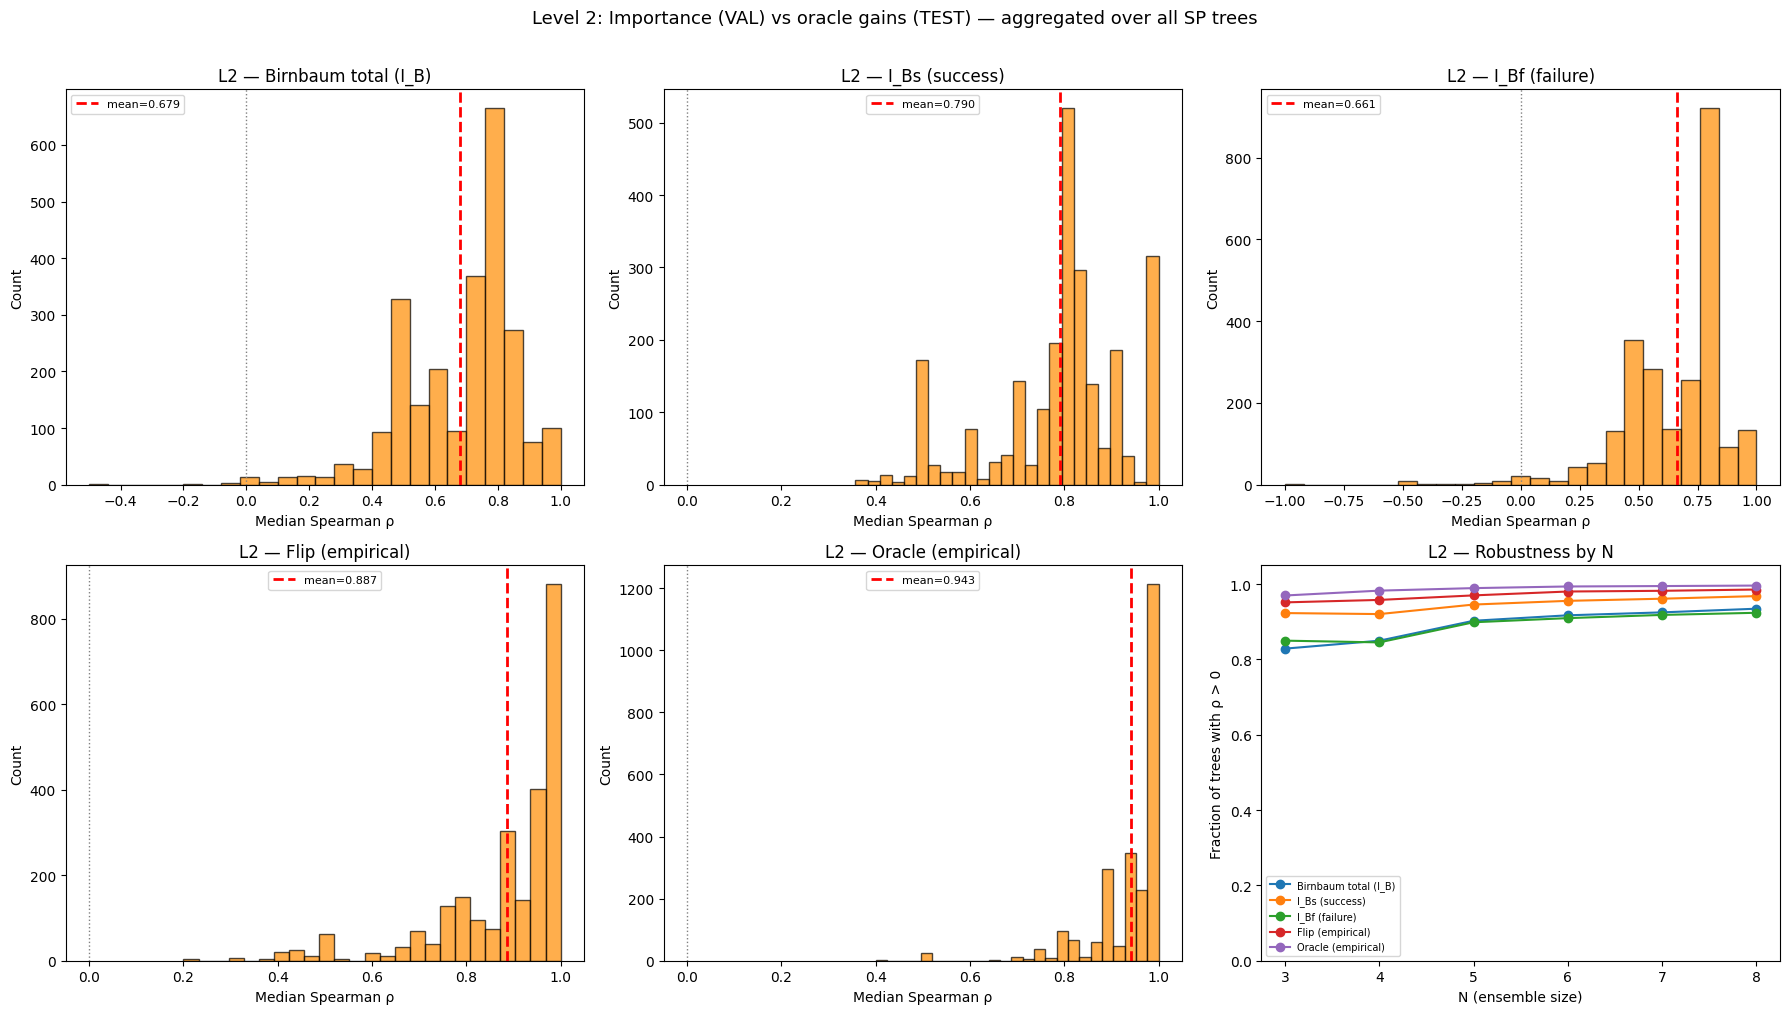

Saved: importance_level2_results.pdf


In [13]:
import matplotlib.pyplot as plt

MEASURES = ["birnbaum", "birn_success", "birn_failure", "flip", "oracle"]
TITLES = ["Birnbaum total (I_B)", "I_Bs (success)", "I_Bf (failure)",
          "Flip (empirical)", "Oracle (empirical)"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

# Row 1: histograms of median Spearman per (dataset, run, N)
for ax, measure, title in zip(axes[:5], MEASURES, TITLES):
    col = f"spearman_{measure}_median"
    valid = df2[col].dropna()
    ax.hist(valid, bins=25, edgecolor="black", alpha=0.7, color="darkorange")
    ax.axvline(valid.mean(), color="red", linestyle="--", lw=2,
               label=f"mean={valid.mean():.3f}")
    ax.axvline(0, color="gray", linestyle=":", lw=1)
    ax.set_xlabel("Median Spearman ρ")
    ax.set_ylabel("Count")
    ax.set_title(f"L2 — {title}")
    ax.legend(fontsize=8)

# Last panel: fraction of trees with rho > 0, per measure and N
ax = axes[5]
for measure, title in zip(MEASURES, TITLES):
    col = f"spearman_{measure}_frac_pos"
    by_N = df2.groupby("N")[col].mean()
    ax.plot(by_N.index, by_N.values, marker="o", label=title)
ax.set_xlabel("N (ensemble size)")
ax.set_ylabel("Fraction of trees with ρ > 0")
ax.set_title("L2 — Robustness by N")
ax.legend(fontsize=7)
ax.set_ylim(0, 1.05)

plt.suptitle("Level 2: Importance (VAL) vs oracle gains (TEST) — aggregated over all SP trees",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("importance_level2_results.pdf", bbox_inches="tight")
plt.show()
print("Saved: importance_level2_results.pdf")